
╔══════════════════════════════════════════════════════════════╗
║   Two-Stage Churn Pipeline  —  Book2.xlsx                    ║
║   Orange-matched: 10 × stratified 80/20, no SMOTE           ║
╚══════════════════════════════════════════════════════════════╝

[0] Loading Book2.xlsx …
  Customer_data  : 2,000 rows | churn rate 46.2%
  Online_casino  : 2,361 rows | at-risk rate 27.5%

  Stage 1 — Churn vs Retained

  ── Test and Score (avg 10 × 80/20 stratified, no SMOTE) ──
                        AUC     CA     F1    Prec  Recall     MCC
Model                                                            
Random Forest        0.9108  0.890  0.890  0.8936  0.8944  0.7880
Logistic Regression  0.9095  0.906  0.906  0.9156  0.9126  0.8282
Tree                 0.8379  0.839  0.838  0.8384  0.8379  0.6764

────────────────────────────────────────────────────────────
  Stage 1 — Churn vs Retained  — Classification Reports
────────────────────────────────────────────────────────────

  ▸ Logisti

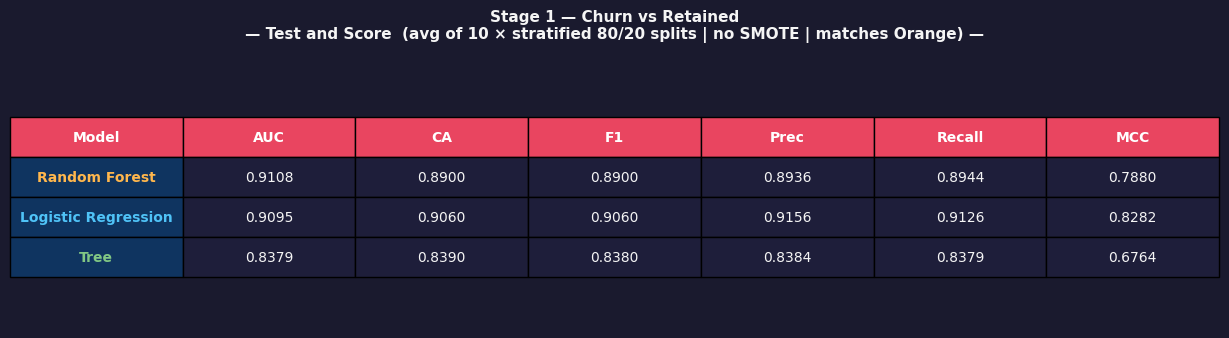

    saved → /content/outputs/s1_test_and_score.png


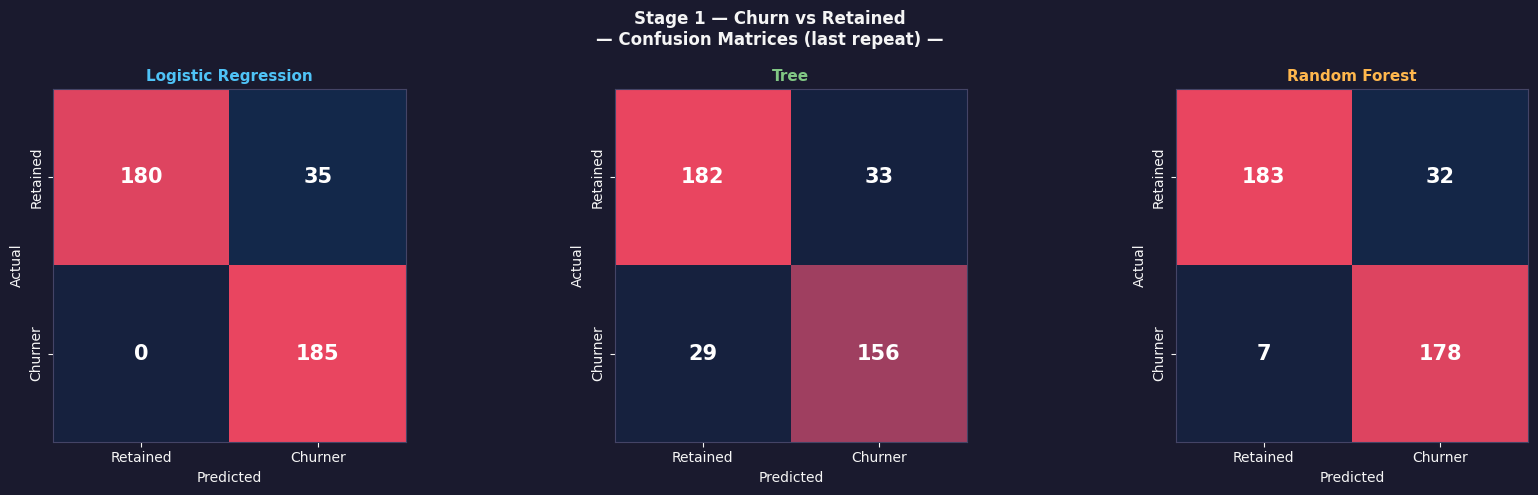

    saved → /content/outputs/s1_confusion_matrices.png


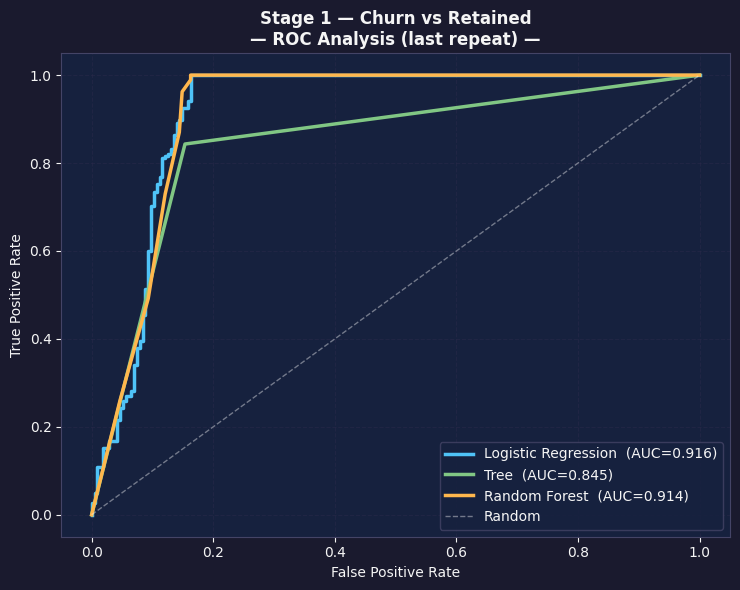

    saved → /content/outputs/s1_roc_analysis.png


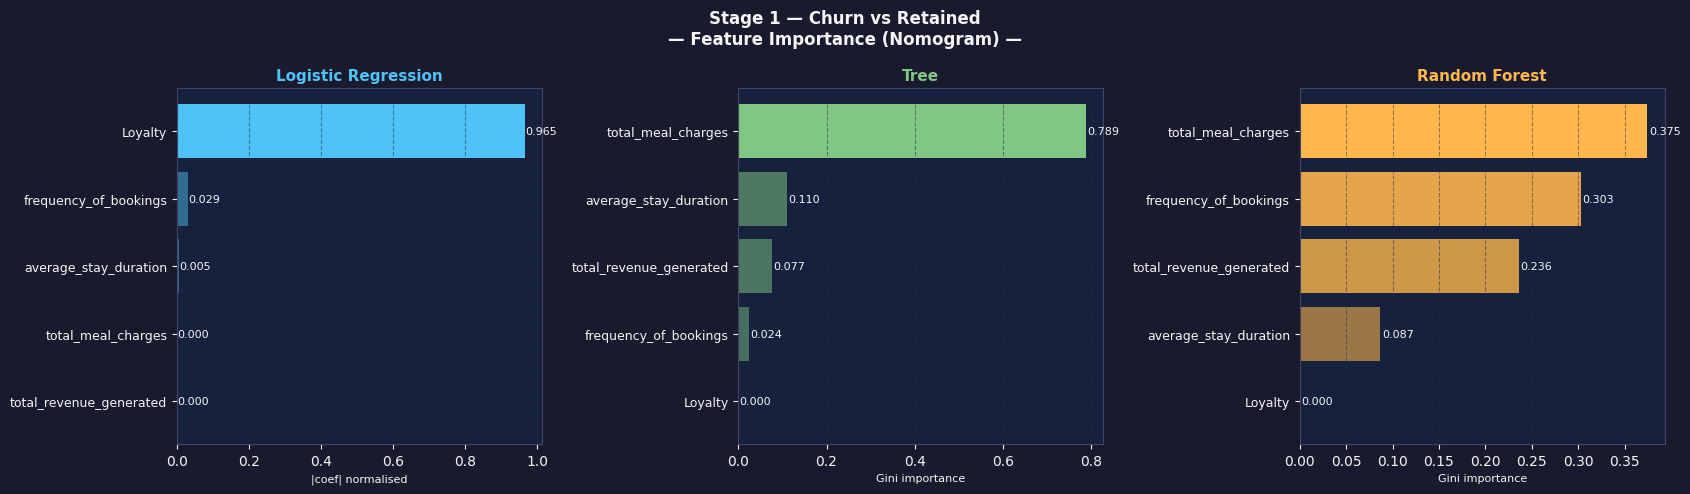

    saved → /content/outputs/s1_feature_importance.png


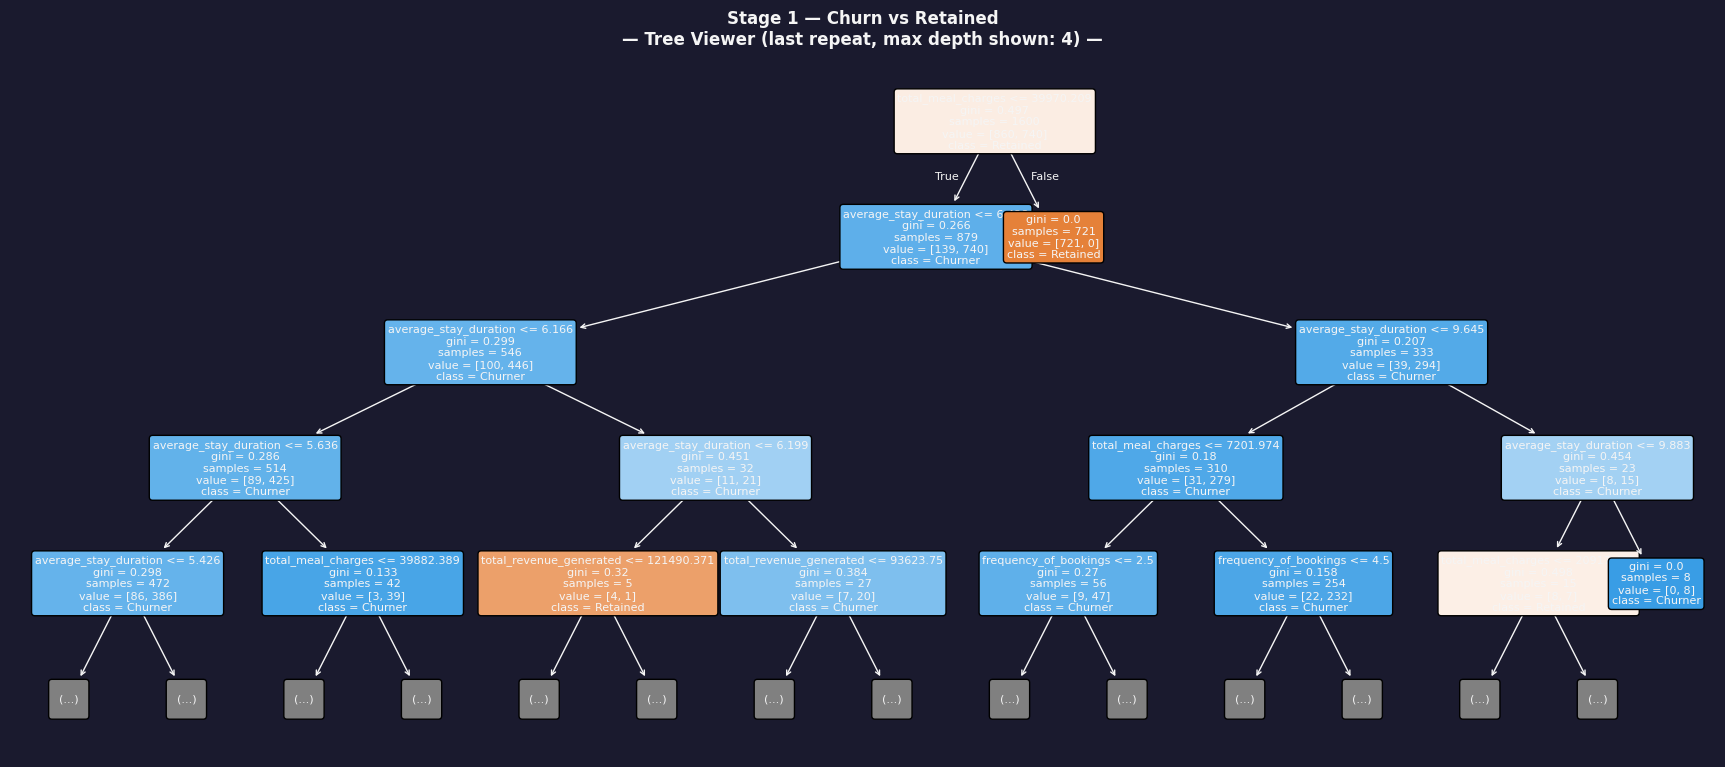

    saved → /content/outputs/s1_tree_viewer.png


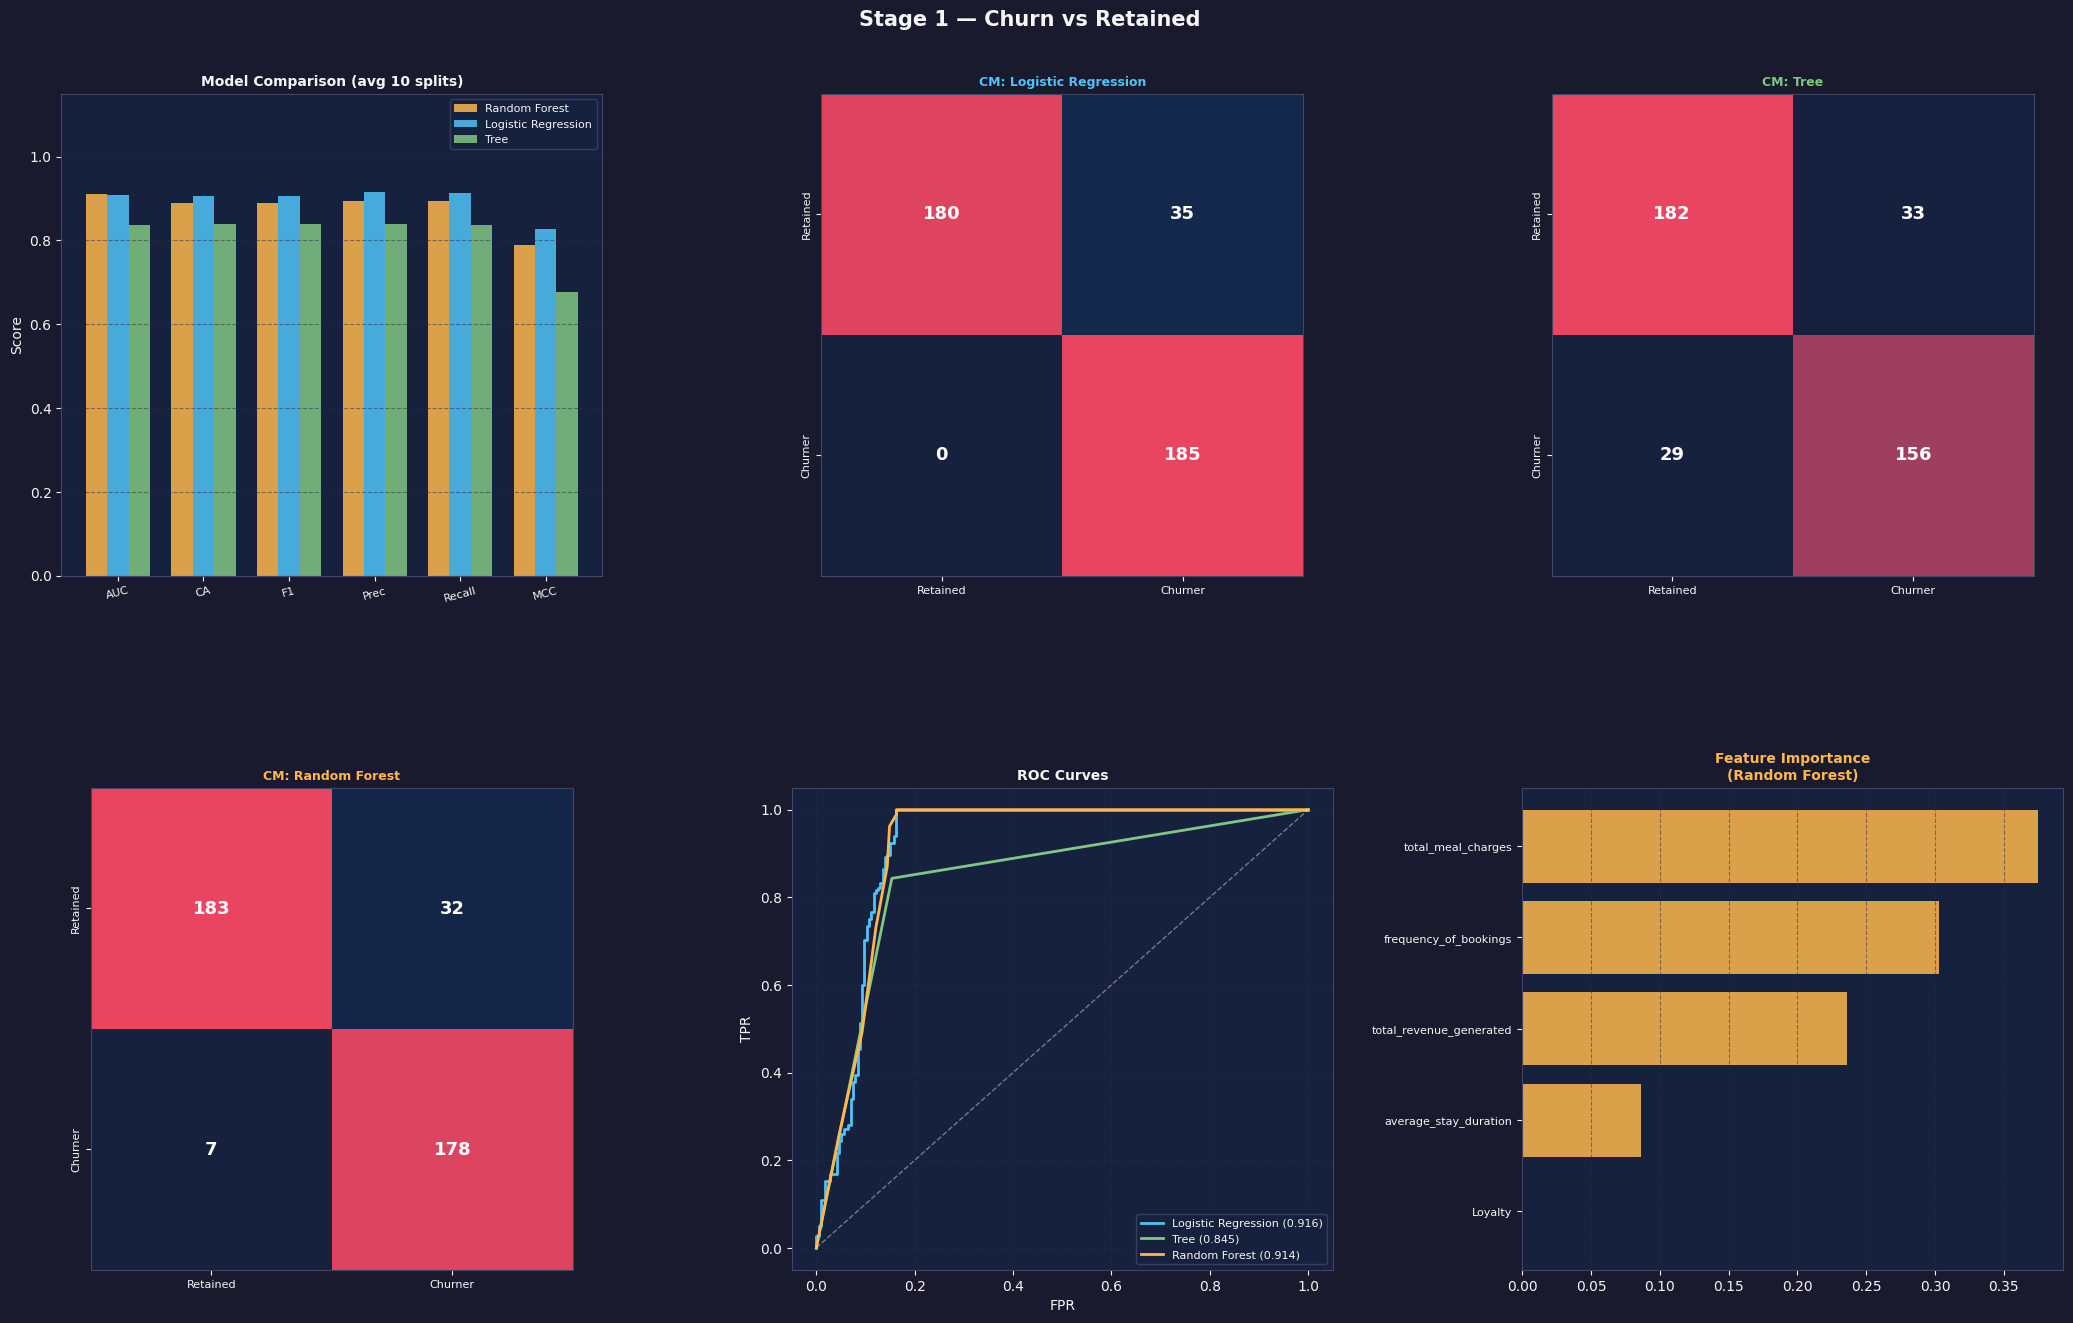

    saved → /content/outputs/s1_dashboard.png
  Computing SHAP (Stage 1) …


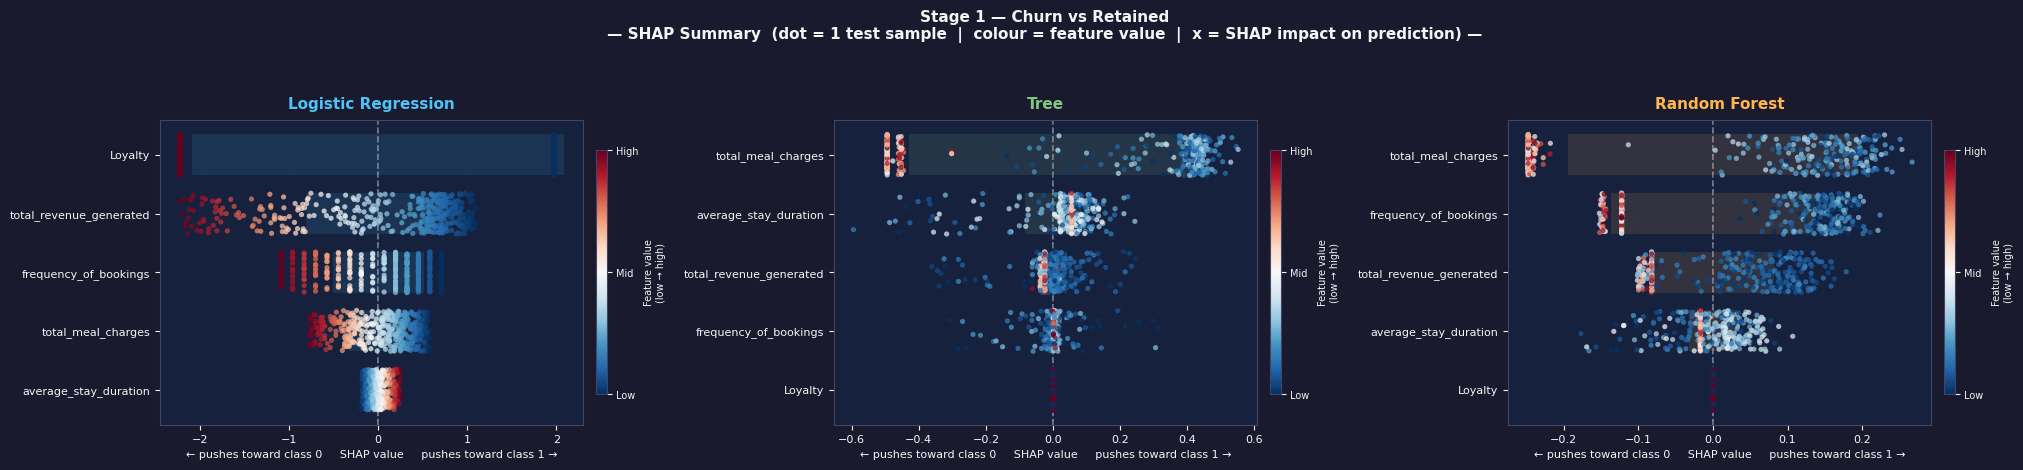

    saved → /content/outputs/s1_shap_summary.png


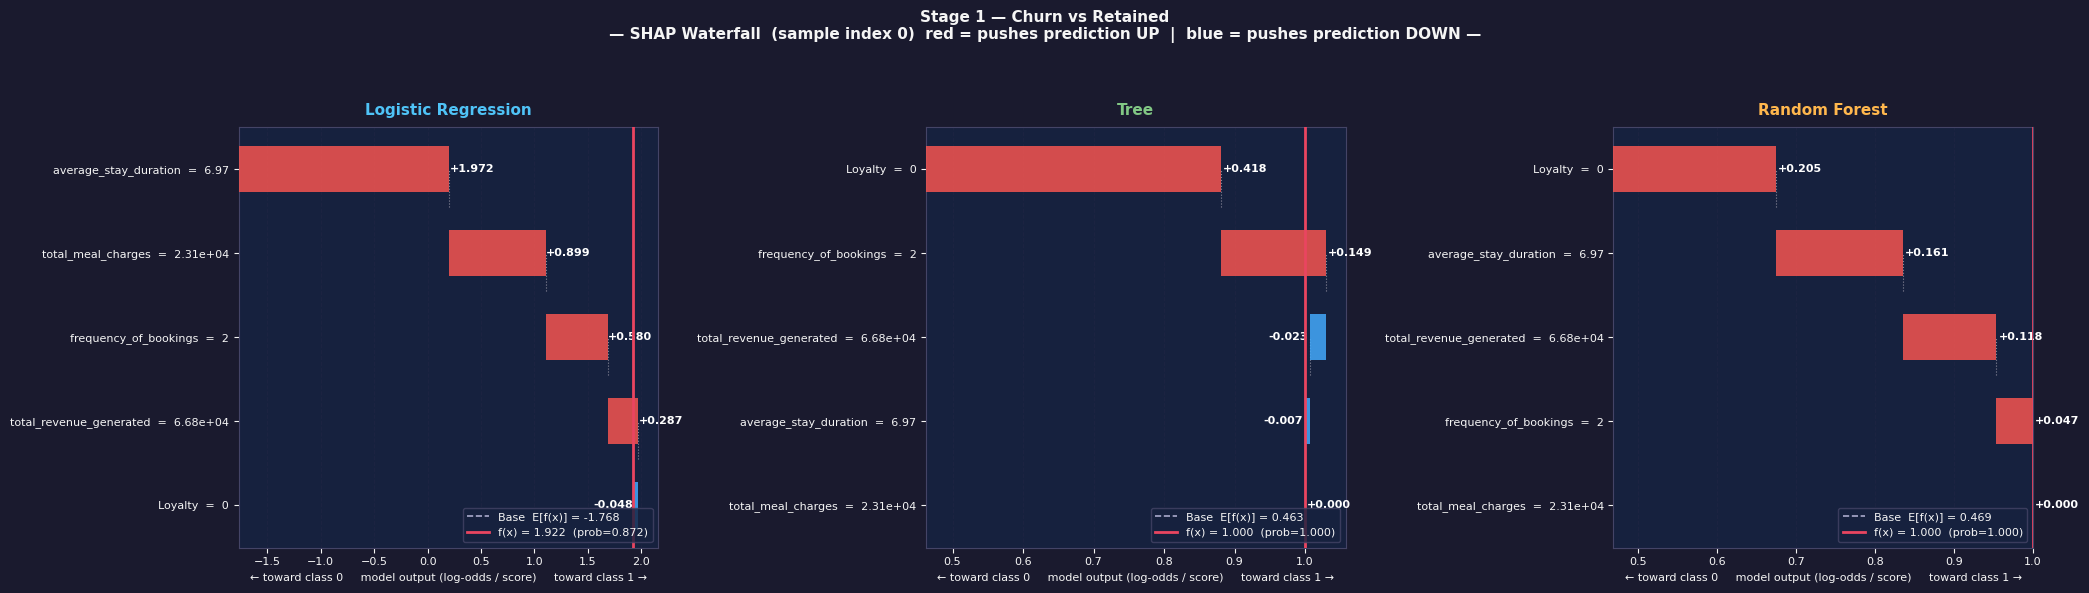

    saved → /content/outputs/s1_shap_waterfall.png

  ✔ Best (AUC): Random Forest  → AUC=0.9108

  Stage 2 — Voluntary Disengagement vs At-Risk Gambling

  ── Test and Score (avg 10 × 80/20 stratified, no SMOTE) ──
                        AUC      CA      F1    Prec  Recall     MCC
Model                                                              
Random Forest        0.9997  0.9926  0.9907  0.9909  0.9906  0.9815
Tree                 0.9935  0.9951  0.9939  0.9943  0.9935  0.9878
Logistic Regression  0.9888  0.9539  0.9407  0.9525  0.9310  0.8831

────────────────────────────────────────────────────────────
  Stage 2 — Voluntary Disengagement vs At-Risk Gambling  — Classification Reports
────────────────────────────────────────────────────────────

  ▸ Logistic Regression
                     precision    recall  f1-score   support

Voluntary Disengage     0.9681    0.9738    0.9709       343
    At-Risk Gambler     0.9297    0.9154    0.9225       130

           accuracy           

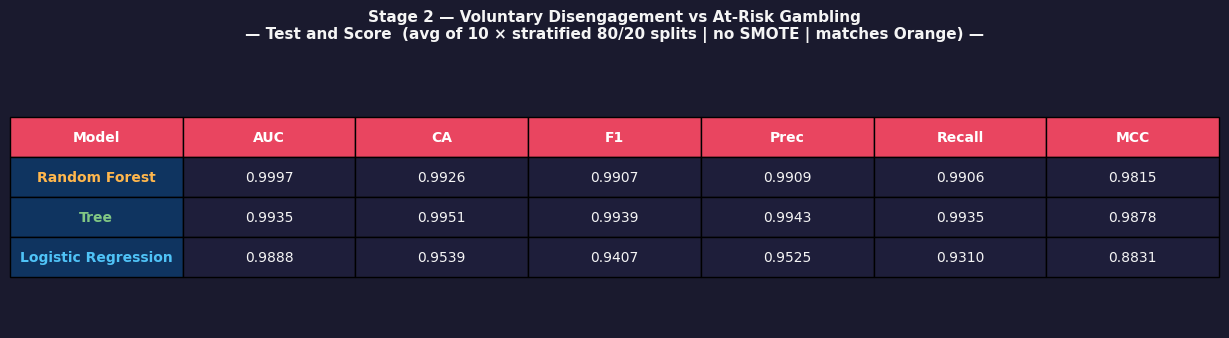

    saved → /content/outputs/s2_test_and_score.png


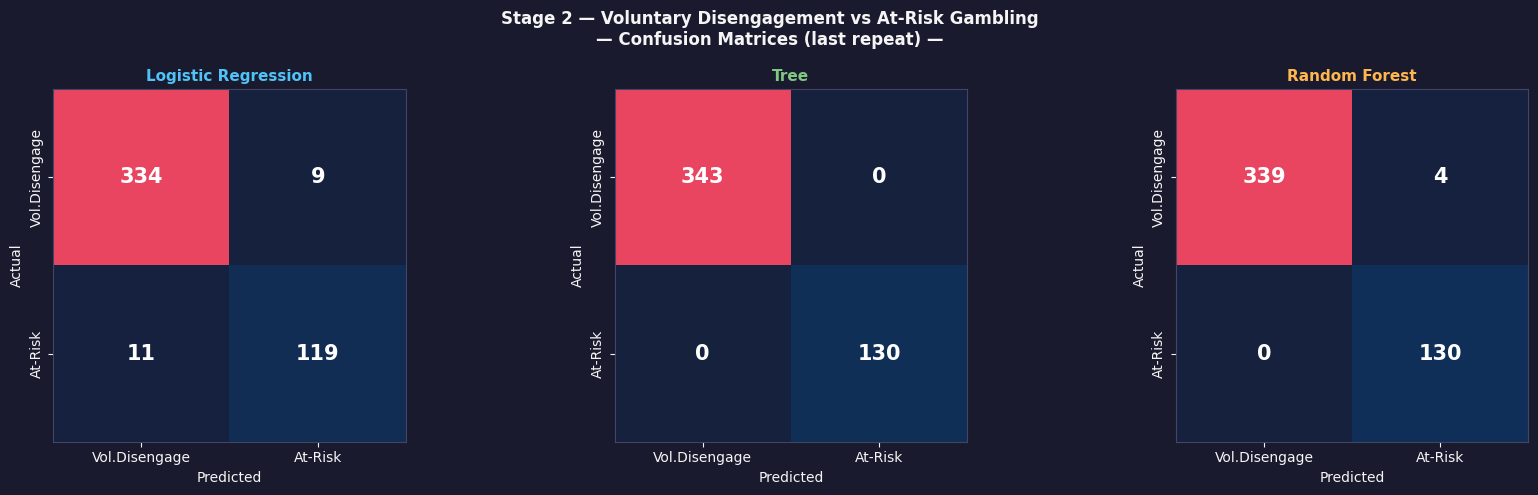

    saved → /content/outputs/s2_confusion_matrices.png


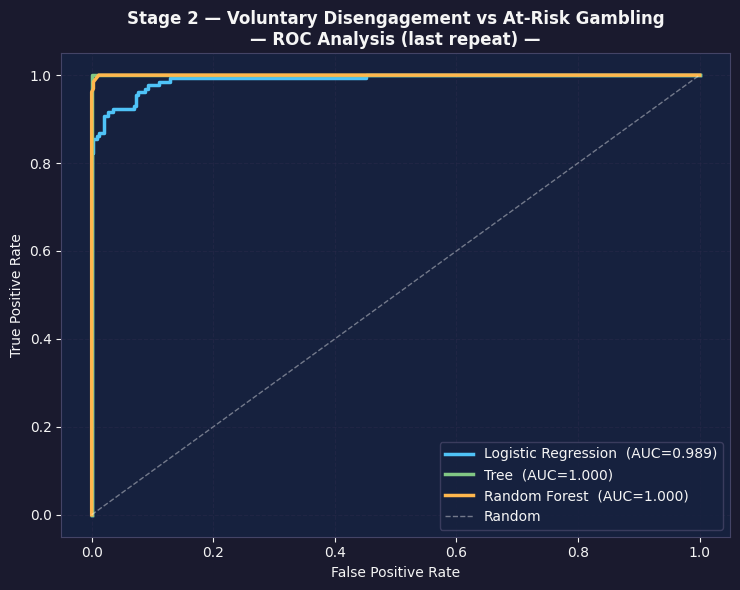

    saved → /content/outputs/s2_roc_analysis.png


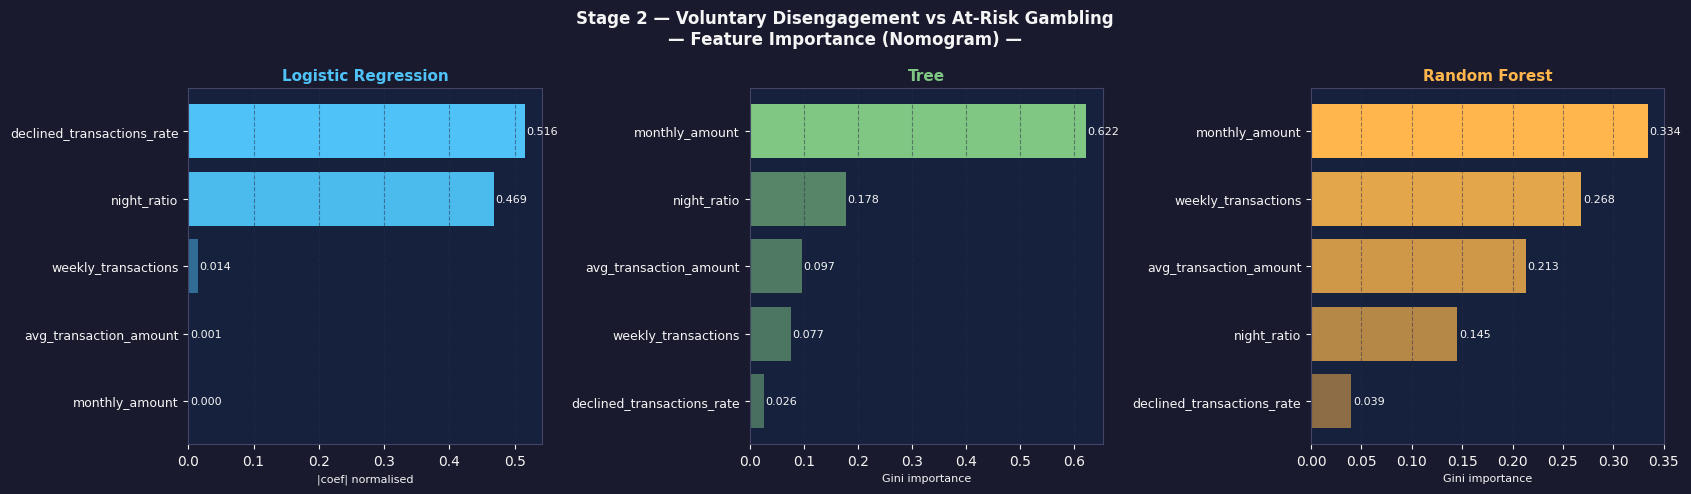

    saved → /content/outputs/s2_feature_importance.png


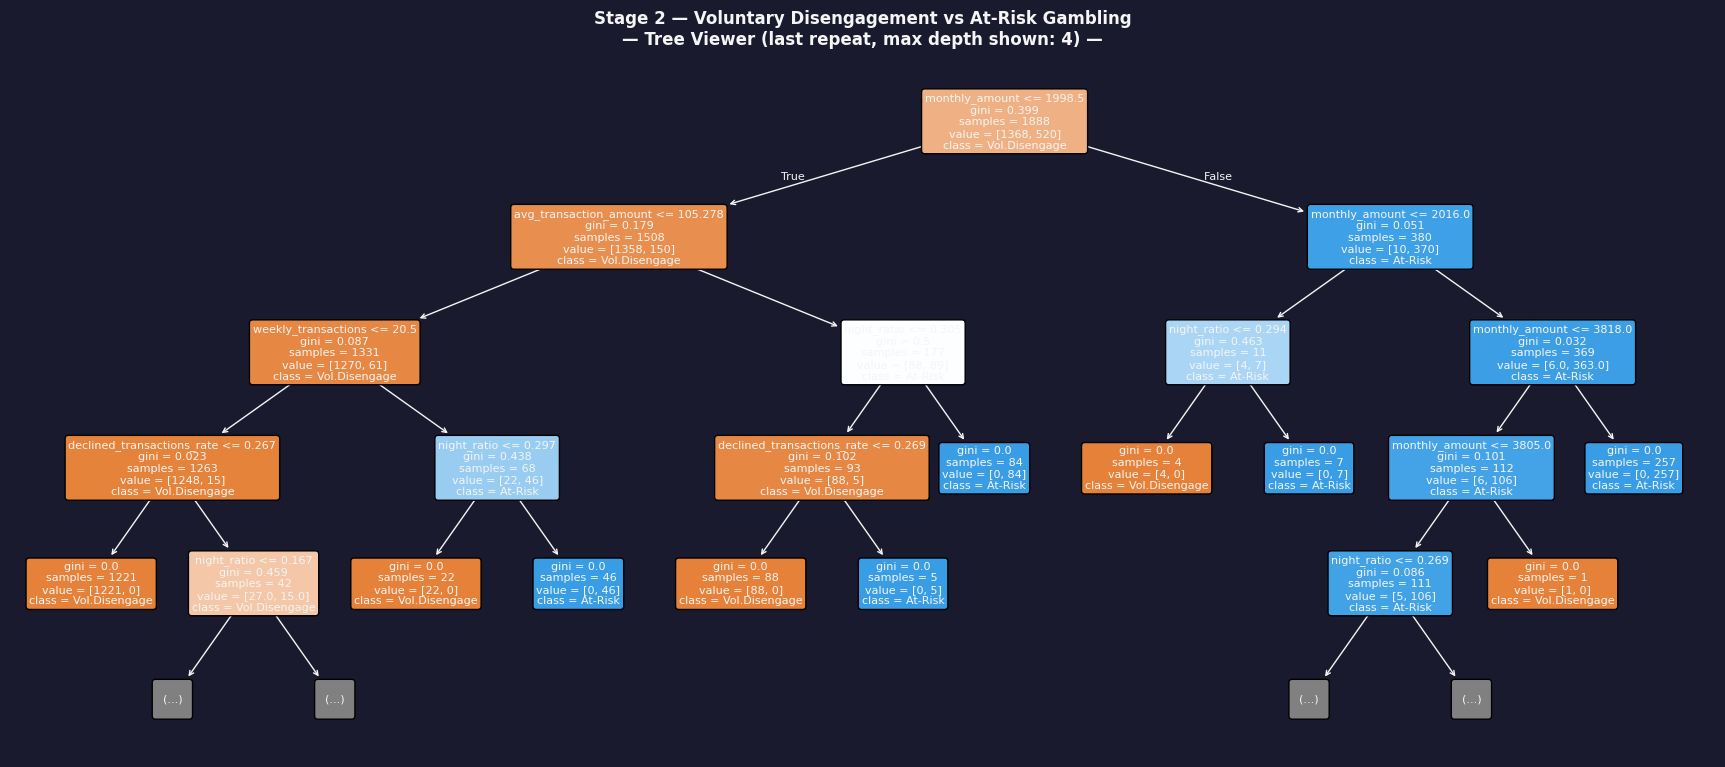

    saved → /content/outputs/s2_tree_viewer.png


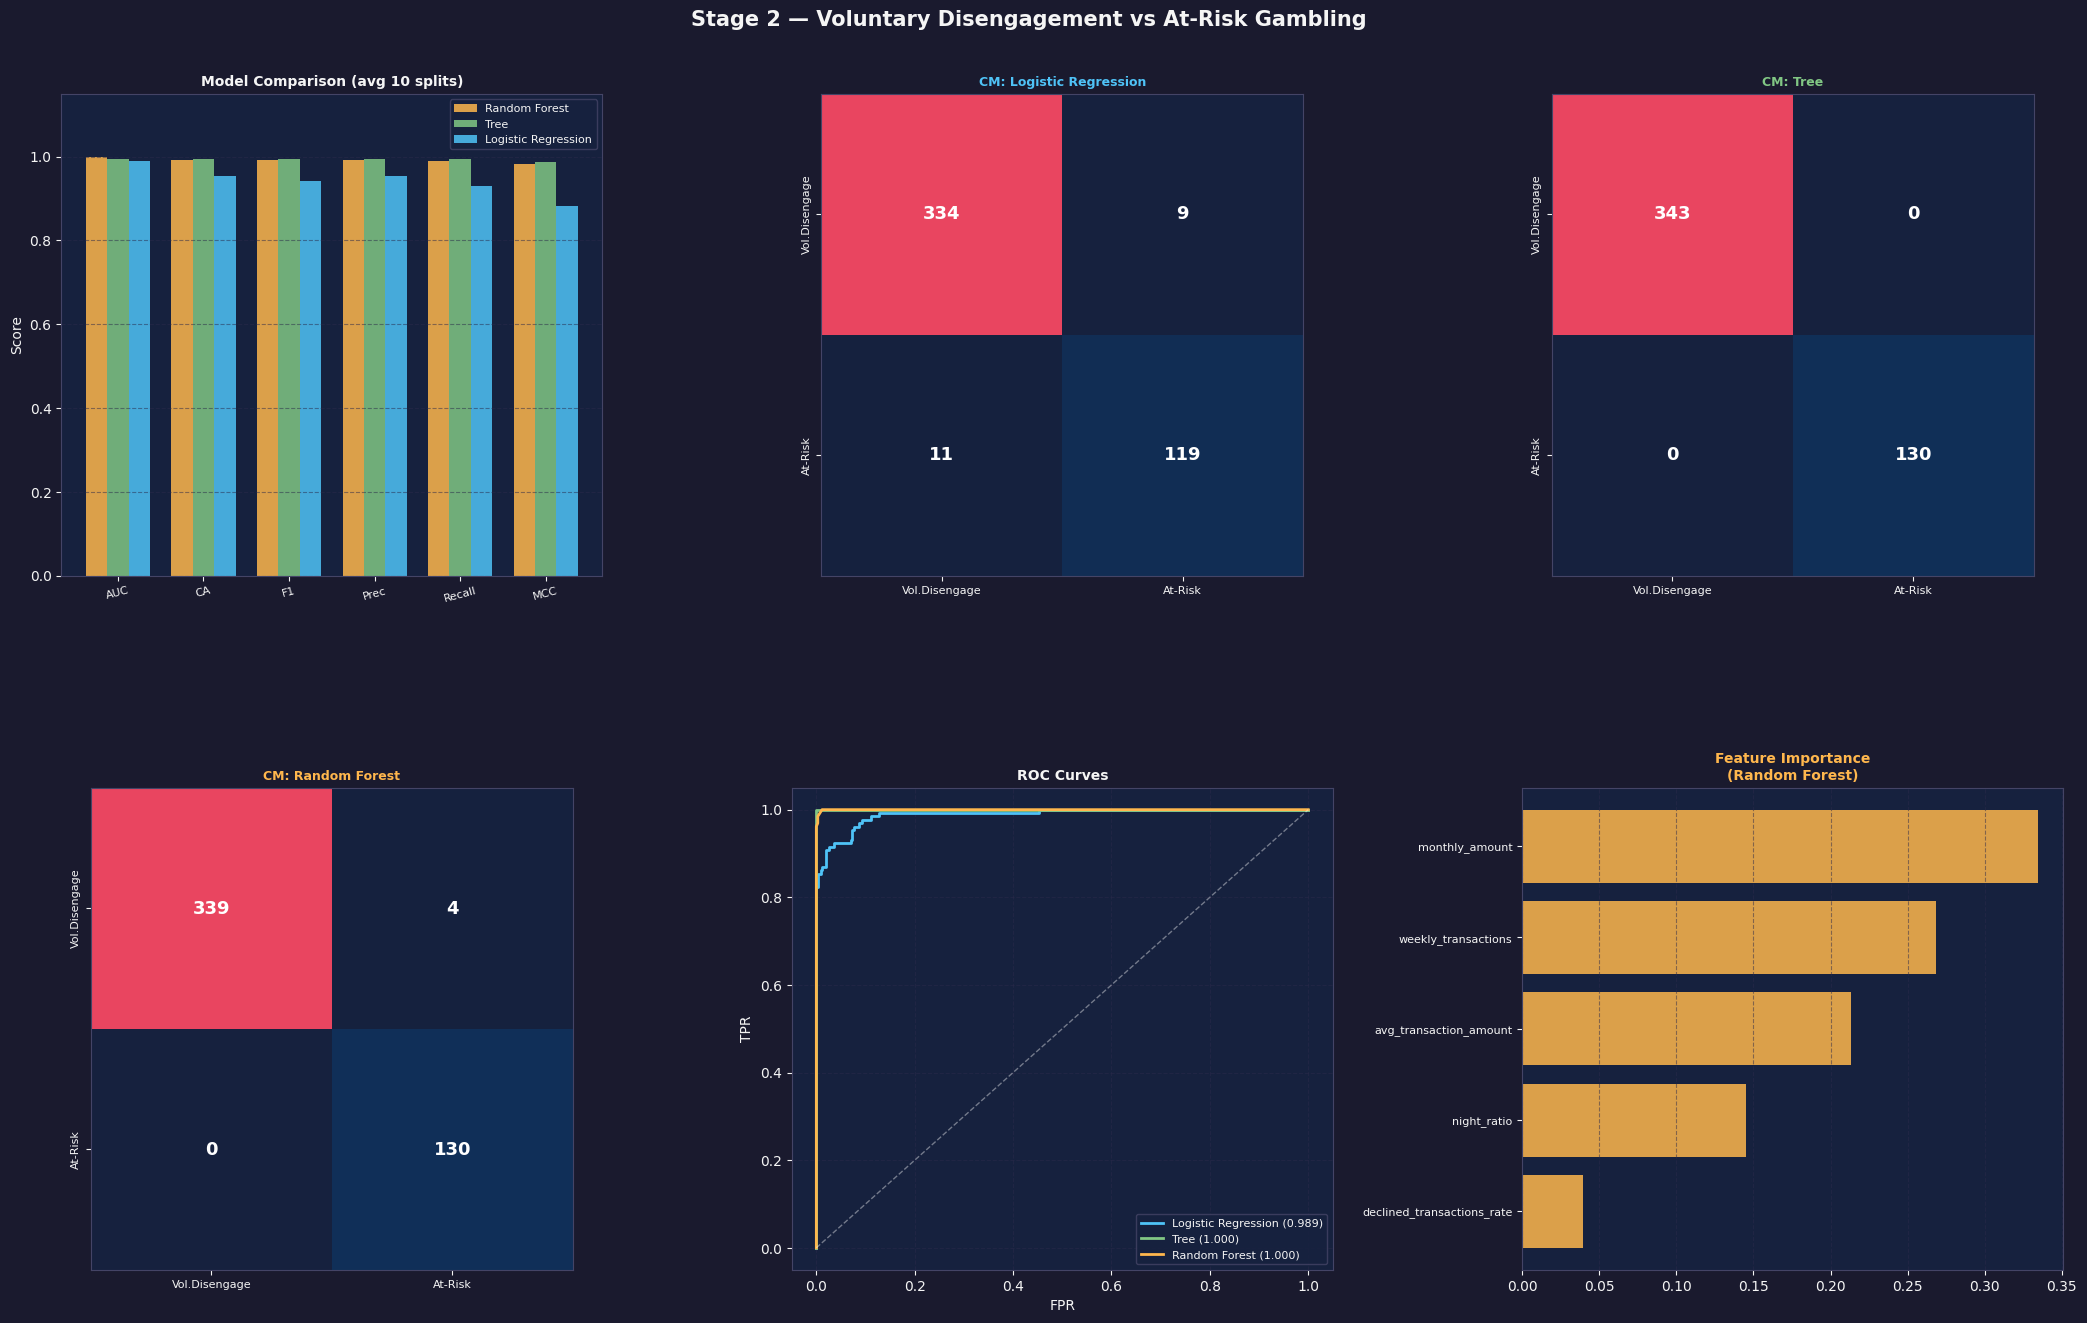

    saved → /content/outputs/s2_dashboard.png
  Computing SHAP (Stage 2) …


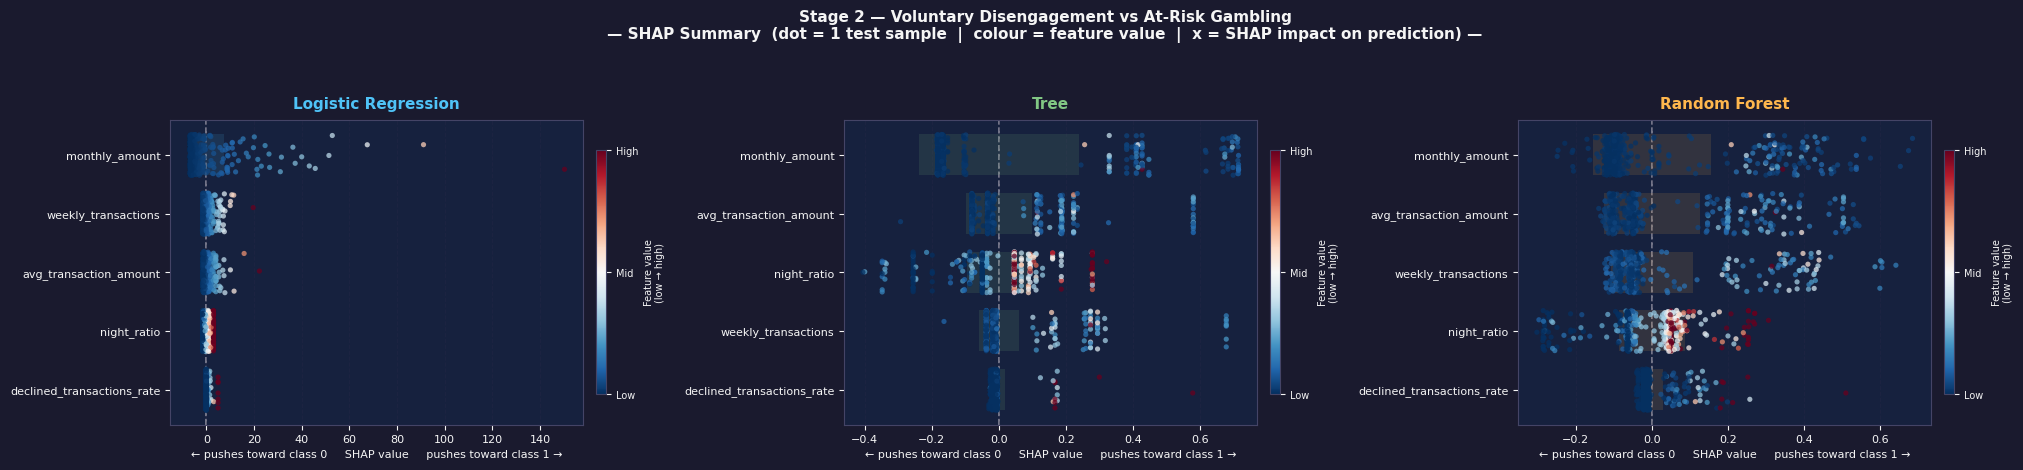

    saved → /content/outputs/s2_shap_summary.png


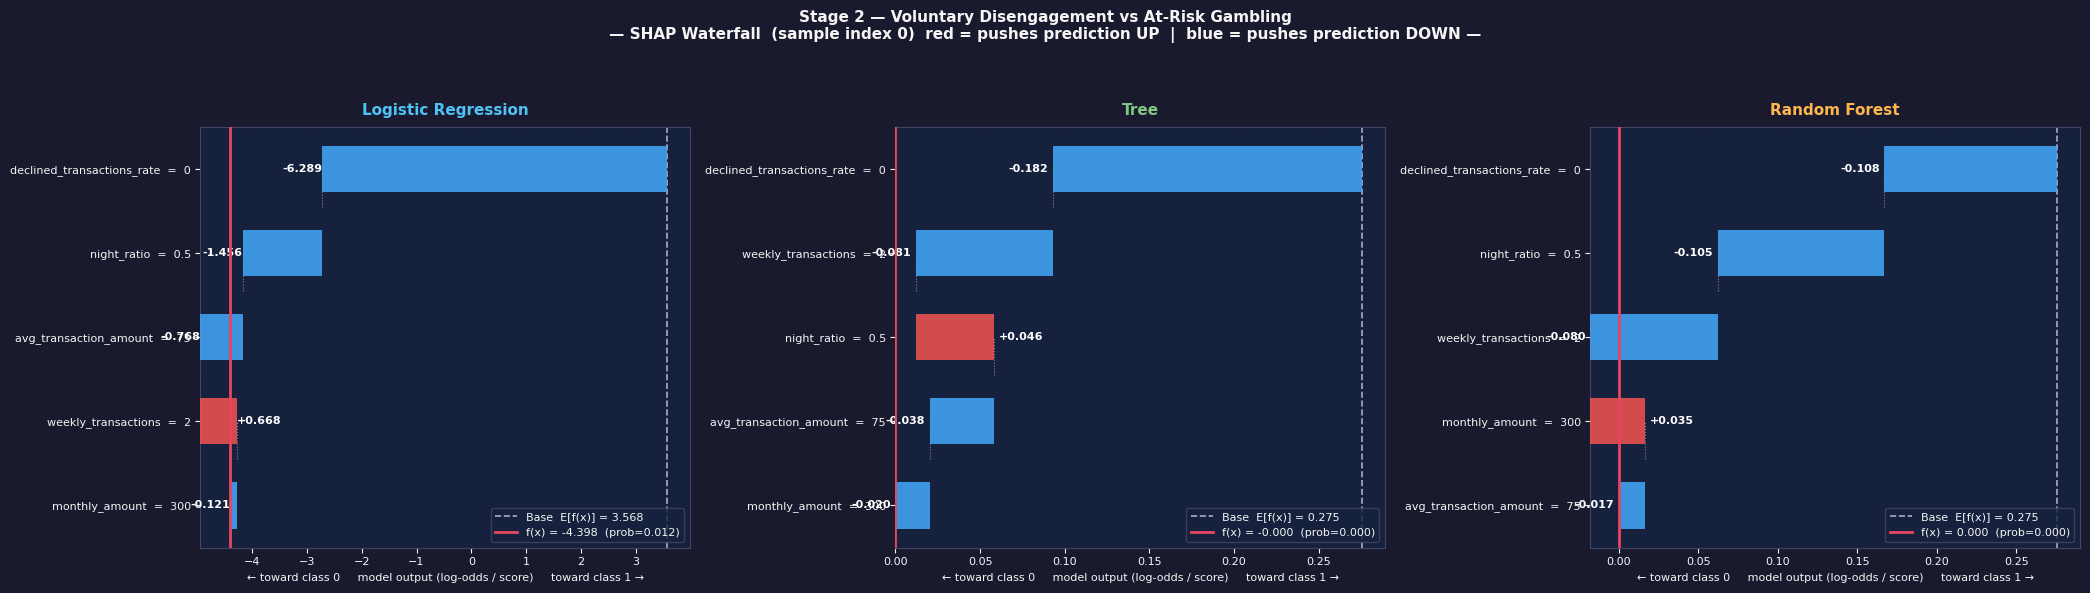

    saved → /content/outputs/s2_shap_waterfall.png

  ✔ Best (AUC): Random Forest  → AUC=0.9997


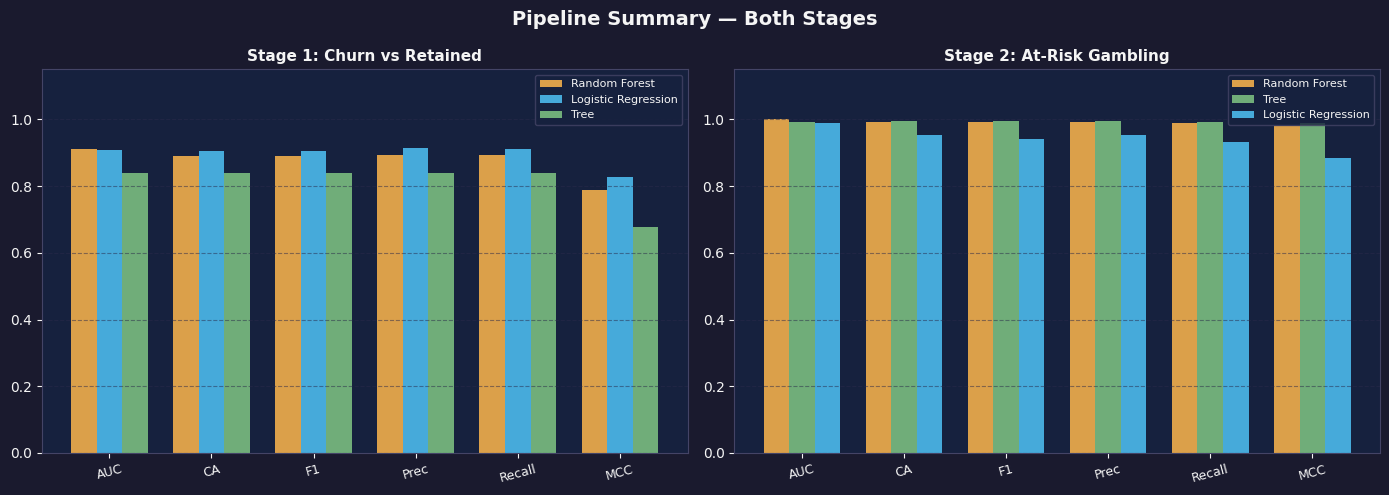

    saved → /content/outputs/pipeline_summary.png

  FINAL RESULTS

Stage 1 — Churn vs Retained:
                        AUC     CA     F1    Prec  Recall     MCC
Model                                                            
Random Forest        0.9108  0.890  0.890  0.8936  0.8944  0.7880
Logistic Regression  0.9095  0.906  0.906  0.9156  0.9126  0.8282
Tree                 0.8379  0.839  0.838  0.8384  0.8379  0.6764

Stage 2 — At-Risk Gambling:
                        AUC      CA      F1    Prec  Recall     MCC
Model                                                              
Random Forest        0.9997  0.9926  0.9907  0.9909  0.9906  0.9815
Tree                 0.9935  0.9951  0.9939  0.9943  0.9935  0.9878
Logistic Regression  0.9888  0.9539  0.9407  0.9525  0.9310  0.8831

Output files (17) → /content/outputs/
  • s1_dashboard.png
  • s2_dashboard.png
  • pipeline_summary.png
  • s1_test_and_score.png
  • s2_test_and_score.png
  • s1_confusion_matrices.png
  • s2_confusion

In [1]:
"""
==============================================================================
Two-Stage Churn Pipeline  —  Bonato Giovanni - A3 (Data6000).xlsx
==============================================================================

 SETTINGS:
  • Test on test data  (NOT cross-validation)
  • Training set size : 80 %
  • Repeat train/test : 10   (stratified random splits, seeds 0-9)
  • Stratified splits : YES
  • Metrics averaged  over the 10 repeats → AUC, CA, F1, Prec, Recall, MCC
  • MCC = Matthews Correlation Coefficient

STAGE 1 │ Customer_data
         │ Features : frequency_of_bookings, total_revenue_generated,
         │            average_stay_duration, total_meal_charges, Loyalty
         │ Target   : Likely churner  (0=Retained, 1=Churner)
         │ NOTE: days_since_last_booking EXCLUDED (target leakage)

STAGE 2 │ Online_casino_DIB
         │ Features : weekly_transactions, avg_transaction_amount,
         │            monthly_amount, declined_transactions_rate, night_ratio
         │ Target   : at_risk_gambler  (0=Vol. disengage, 1=At-risk)

==============================================================================
"""

import os
import pathlib
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

# ── matplotlib: inline in Colab/Jupyter, file-only elsewhere ─────────────────
try:
    from IPython import get_ipython as _gip
    _shell = _gip()
    if _shell and "ZMQ" in type(_shell).__name__:
        pass  # already inline
    else:
        import matplotlib
        matplotlib.use("Agg")
except Exception:
    import matplotlib
    matplotlib.use("Agg")

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import (
    roc_auc_score, accuracy_score, f1_score,
    precision_score, recall_score, matthews_corrcoef,
    confusion_matrix, roc_curve, classification_report,
)

# ── Palette ───────────────────────────────────────────────────────────────────
C_DARK   = "#1a1a2e"
C_MID    = "#16213e"
C_ACCENT = "#e94560"
C_BLUE   = "#0f3460"
C_LIGHT  = "#f5f5f5"
MODEL_COLORS = {
    "Logistic Regression": "#4fc3f7",
    "Tree":                "#81c784",
    "Random Forest":       "#ffb74d",
}

plt.rcParams.update({
    "figure.facecolor": C_DARK, "axes.facecolor":   C_MID,
    "axes.edgecolor":   "#444466", "axes.labelcolor": C_LIGHT,
    "xtick.color":      C_LIGHT,  "ytick.color":      C_LIGHT,
    "text.color":       C_LIGHT,  "grid.color":       "#2a2a4a",
    "grid.linestyle":   "--",     "grid.alpha":        0.5,
    "legend.facecolor": C_MID,    "legend.edgecolor": "#444466",
    "font.size": 10,
})

# ── Output directory ──────────────────────────────────────────────────────────
def _resolve_output() -> str:
    if pathlib.Path("/content").exists():
        p = pathlib.Path("/content/outputs")
    else:
        p = pathlib.Path("outputs")
    p.mkdir(parents=True, exist_ok=True)
    return str(p)

OUTPUT = _resolve_output()

# ── Model configs matching Orange defaults ────────────────────────────────────
MODELS = {
    "Logistic Regression": LogisticRegression(
        C=1.2045,        # Orange C_index=61 decoded from log scale [0.001, 100]
        max_iter=10_000, # allow full convergence (Orange's LR was unscaled/broken)
        random_state=42,
    ),
    "Tree": DecisionTreeClassifier(
        max_depth=None,       # Orange default: no depth limit
        min_samples_split=2,  # Orange default
        min_samples_leaf=1,   # Orange default
        random_state=42,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=10,     # Orange default
        max_depth=None,      # Orange default: unlimited
        max_features="sqrt", # Orange default
        min_samples_split=2,
        random_state=42,
    ),
}


# =============================================================================
# 1.  LOAD DATA
# =============================================================================

def load_data(path: str = "/content/Bonato Giovanni - A3 (Data6000).xlsx"):
    raw1 = pd.read_excel(path, sheet_name="Customer_data")
    raw2 = pd.read_excel(path, sheet_name="Online_casino_DIB")

    S1_FEATURES = [
        "frequency_of_bookings",
        "total_revenue_generated",
        "average_stay_duration",
        "total_meal_charges",
        "Loyalty",
    ]
    S2_FEATURES = [
        "weekly_transactions",
        "avg_transaction_amount",
        "monthly_amount",
        "declined_transactions_rate",
        "night_ratio",
    ]

    cdf = raw1[S1_FEATURES + ["Likely churner"]].dropna().copy()
    cdf.rename(columns={"Likely churner": "target"}, inplace=True)

    gdf = raw2[S2_FEATURES + ["at_risk_gambler"]].dropna().copy()
    gdf.rename(columns={"at_risk_gambler": "target"}, inplace=True)

    print(f"  Customer_data  : {len(cdf):,} rows | churn rate {cdf['target'].mean():.1%}")
    print(f"  Online_casino  : {len(gdf):,} rows | at-risk rate {gdf['target'].mean():.1%}")
    return cdf, S1_FEATURES, gdf, S2_FEATURES


# =============================================================================
# 2.  EVALUATION  (10 × stratified 80/20)
# =============================================================================

def orange_evaluate(df: pd.DataFrame, features: list,
                    n_repeats: int = 10, test_size: float = 0.20):

    X = df[features].values
    y = df["target"].values

    accum      = {name: [] for name in MODELS}
    last_fitted = {}
    last_y_te   = None
    last_X_te   = None   # ← NEW: keep test-set features for SHAP

    for seed in range(n_repeats):
        sss = StratifiedShuffleSplit(
            n_splits=1, test_size=test_size, random_state=seed)
        tr_idx, te_idx = next(sss.split(X, y))
        X_tr, X_te = X[tr_idx], X[te_idx]
        y_tr, y_te = y[tr_idx], y[te_idx]

        for name, clf_tmpl in MODELS.items():
            clf = clf_tmpl.__class__(**clf_tmpl.get_params())
            clf.fit(X_tr, y_tr)
            yp   = clf.predict(X_te)
            prob = clf.predict_proba(X_te)[:, 1]

            accum[name].append({
                "AUC":    roc_auc_score(y_te, prob),
                "CA":     accuracy_score(y_te, yp),
                "F1":     f1_score(y_te, yp, average="macro", zero_division=0),
                "Prec":   precision_score(y_te, yp, average="macro", zero_division=0),
                "Recall": recall_score(y_te, yp, average="macro", zero_division=0),
                "MCC":    matthews_corrcoef(y_te, yp),
            })

            if seed == n_repeats - 1:   # keep last repeat for plots
                last_fitted[name] = (clf, yp, prob)

        if seed == n_repeats - 1:
            last_y_te = y_te
            last_X_te = X_te   # ← NEW

    rows = []
    for name, runs in accum.items():
        avg = {k: np.mean([r[k] for r in runs]) for k in runs[0]}
        rows.append({"Model": name, **{k: round(v, 4) for k, v in avg.items()}})

    metrics = (pd.DataFrame(rows)
                 .set_index("Model")
                 .sort_values("AUC", ascending=False))
    return metrics, last_fitted, last_y_te, last_X_te   # ← returns X_te too


# =============================================================================
# 3.  PLOTS
# =============================================================================

def _save(fig, name: str):
    path = f"{OUTPUT}/{name}"
    fig.savefig(path, dpi=150, bbox_inches="tight",
                facecolor=fig.get_facecolor())
    try:
        from IPython.display import display as _d
        _d(fig)
    except Exception:
        pass
    plt.close(fig)
    print(f"    saved → {path}")


def plot_test_and_score(metrics: pd.DataFrame, title: str, fname: str):
    fig, ax = plt.subplots(figsize=(12, 3.4), facecolor=C_DARK)
    ax.set_facecolor(C_DARK); ax.axis("off")

    cols = ["Model"] + list(metrics.columns)
    data = [[idx] + [f"{v:.4f}" for v in row]
            for idx, row in metrics.iterrows()]

    tbl = ax.table(cellText=data, colLabels=cols,
                   loc="center", cellLoc="center")
    tbl.auto_set_font_size(False); tbl.set_fontsize(10); tbl.scale(1.3, 2.4)

    for j in range(len(cols)):
        tbl[(0, j)].set_facecolor(C_ACCENT)
        tbl[(0, j)].set_text_props(color="white", fontweight="bold")

    for i, idx in enumerate(metrics.index, 1):
        for j in range(len(cols)):
            tbl[(i, j)].set_facecolor("#1e1e3a")
            tbl[(i, j)].set_text_props(color=C_LIGHT)
        tbl[(i, 0)].set_facecolor(C_BLUE)
        tbl[(i, 0)].set_text_props(color=MODEL_COLORS[idx], fontweight="bold")

    ax.set_title(
        f"{title}\n— Test and Score  "
        f"(avg of 10 × stratified 80/20 splits | no SMOTE | matches Orange) —",
        color=C_LIGHT, fontsize=11, fontweight="bold", pad=20)
    _save(fig, fname)


def plot_confusion_matrices(fitted: dict, y_te, class_names: list,
                             title: str, fname: str):
    fig, axes = plt.subplots(1, 3, figsize=(17, 5), facecolor=C_DARK)
    fig.suptitle(f"{title}\n— Confusion Matrices (last repeat) —",
                 color=C_LIGHT, fontsize=12, fontweight="bold")
    cmap = LinearSegmentedColormap.from_list("c", [C_MID, C_BLUE, C_ACCENT])

    for ax, (name, (clf, yp, _)) in zip(axes, fitted.items()):
        cm = confusion_matrix(y_te, yp)
        ax.imshow(cm, cmap=cmap)
        ax.set_title(name, color=MODEL_COLORS[name],
                     fontsize=11, fontweight="bold")
        ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
        ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xticklabels(class_names)
        ax.set_yticklabels(class_names, rotation=90, va="center")
        for (r, c), v in np.ndenumerate(cm):
            ax.text(c, r, str(v), ha="center", va="center",
                    color="white", fontsize=15, fontweight="bold")
    plt.tight_layout()
    _save(fig, fname)


def plot_roc_curves(fitted: dict, y_te, title: str, fname: str):
    fig, ax = plt.subplots(figsize=(7.5, 6), facecolor=C_DARK)
    ax.set_facecolor(C_MID)
    ax.set_title(f"{title}\n— ROC Analysis (last repeat) —",
                 color=C_LIGHT, fontsize=12, fontweight="bold")
    for name, (_, _, prob) in fitted.items():
        fpr, tpr, _ = roc_curve(y_te, prob)
        auc = roc_auc_score(y_te, prob)
        ax.plot(fpr, tpr, lw=2.5, color=MODEL_COLORS[name],
                label=f"{name}  (AUC={auc:.3f})")
    ax.plot([0, 1], [0, 1], "w--", lw=1, alpha=0.4, label="Random")
    ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
    ax.legend(loc="lower right"); ax.grid(True)
    plt.tight_layout()
    _save(fig, fname)


def plot_feature_importance(fitted: dict, features: list,
                             title: str, fname: str):
    fig, axes = plt.subplots(1, 3, figsize=(17, 5), facecolor=C_DARK)
    fig.suptitle(f"{title}\n— Feature Importance (Nomogram) —",
                 color=C_LIGHT, fontsize=12, fontweight="bold")
    for ax, (name, (clf, _, _)) in zip(axes, fitted.items()):
        if hasattr(clf, "feature_importances_"):
            imp  = clf.feature_importances_
            kind = "Gini importance"
        else:
            imp  = np.abs(clf.coef_[0]); imp /= imp.sum()
            kind = "|coef| normalised"
        idx  = np.argsort(imp)
        bars = ax.barh(range(len(idx)), imp[idx],
                       color=MODEL_COLORS[name], alpha=0.85, edgecolor="none")
        for bar, v in zip(bars, imp[idx]):
            bar.set_alpha(0.45 + 0.55 * v / (imp.max() + 1e-9))
        ax.set_yticks(range(len(idx)))
        ax.set_yticklabels([features[i] for i in idx], fontsize=9)
        ax.set_xlabel(kind, fontsize=8)
        ax.set_title(name, color=MODEL_COLORS[name],
                     fontsize=11, fontweight="bold")
        ax.set_facecolor(C_MID); ax.grid(axis="x")
        for i, (_, v) in enumerate(zip(bars, imp[idx])):
            ax.text(v + 0.002, i, f"{v:.3f}", va="center",
                    color=C_LIGHT, fontsize=8)
    plt.tight_layout()
    _save(fig, fname)


def plot_tree_viewer(fitted: dict, features: list, class_names: list,
                     title: str, fname: str):
    clf = fitted["Tree"][0]
    fig, ax = plt.subplots(figsize=(22, 9), facecolor=C_DARK)
    ax.set_facecolor(C_DARK)
    plot_tree(clf, feature_names=features, class_names=class_names,
              filled=True, rounded=True, fontsize=8, ax=ax, max_depth=4)
    ax.set_title(f"{title}\n— Tree Viewer (last repeat, max depth shown: 4) —",
                 color=C_LIGHT, fontsize=12, fontweight="bold", pad=14)
    _save(fig, fname)


def plot_dashboard(metrics: pd.DataFrame, fitted: dict, y_te,
                   features: list, class_names: list,
                   title: str, fname: str):
    fig = plt.figure(figsize=(22, 14), facecolor=C_DARK)
    gs  = gridspec.GridSpec(2, 3, figure=fig,
                            hspace=0.44, wspace=0.35,
                            top=0.90, bottom=0.06,
                            left=0.06, right=0.97)
    fig.suptitle(title, color=C_LIGHT, fontsize=15,
                 fontweight="bold", y=0.96)

    # Metric bars
    ax0  = fig.add_subplot(gs[0, 0])
    cols = ["AUC", "CA", "F1", "Prec", "Recall", "MCC"]
    x = np.arange(len(cols)); w = 0.25
    for i, (name, row) in enumerate(metrics.iterrows()):
        ax0.bar(x + (i - 1) * w, [row[c] for c in cols], w,
                label=name, color=MODEL_COLORS[name], alpha=0.85)
    ax0.set_xticks(x); ax0.set_xticklabels(cols, fontsize=8, rotation=15)
    ax0.set_ylim(0, 1.15); ax0.set_ylabel("Score")
    ax0.set_title("Model Comparison (avg 10 splits)",
                  color=C_LIGHT, fontsize=10, fontweight="bold")
    ax0.legend(fontsize=8); ax0.grid(axis="y")

    # Confusion matrices
    cmap = LinearSegmentedColormap.from_list("c", [C_MID, C_BLUE, C_ACCENT])
    for col_idx, (name, (clf, yp, _)) in enumerate(fitted.items()):
        pos = [(0, 1), (0, 2), (1, 0)][col_idx]
        ax  = fig.add_subplot(gs[pos[0], pos[1]])
        cm  = confusion_matrix(y_te, yp)
        ax.imshow(cm, cmap=cmap)
        ax.set_title(f"CM: {name}", color=MODEL_COLORS[name],
                     fontsize=9, fontweight="bold")
        ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xticklabels(class_names, fontsize=8)
        ax.set_yticklabels(class_names, fontsize=8, rotation=90, va="center")
        for (r, c), v in np.ndenumerate(cm):
            ax.text(c, r, str(v), ha="center", va="center",
                    color="white", fontsize=13, fontweight="bold")

    # ROC
    ax_r = fig.add_subplot(gs[1, 1])
    for name, (_, _, prob) in fitted.items():
        fpr, tpr, _ = roc_curve(y_te, prob)
        auc = roc_auc_score(y_te, prob)
        ax_r.plot(fpr, tpr, lw=2, color=MODEL_COLORS[name],
                  label=f"{name} ({auc:.3f})")
    ax_r.plot([0, 1], [0, 1], "w--", lw=1, alpha=0.4)
    ax_r.set_xlabel("FPR"); ax_r.set_ylabel("TPR")
    ax_r.set_title("ROC Curves", color=C_LIGHT, fontsize=10, fontweight="bold")
    ax_r.legend(fontsize=8, loc="lower right"); ax_r.grid(True)

    # Feature importance
    ax_f = fig.add_subplot(gs[1, 2])
    best = metrics.index[0]
    clf  = fitted[best][0]
    imp  = (clf.feature_importances_ if hasattr(clf, "feature_importances_")
            else np.abs(clf.coef_[0]) / np.abs(clf.coef_[0]).sum())
    idx  = np.argsort(imp)
    ax_f.barh(range(len(idx)), imp[idx], color=MODEL_COLORS[best], alpha=0.85)
    ax_f.set_yticks(range(len(idx)))
    ax_f.set_yticklabels([features[i] for i in idx], fontsize=8)
    ax_f.set_title(f"Feature Importance\n({best})",
                   color=MODEL_COLORS[best], fontsize=10, fontweight="bold")
    ax_f.grid(axis="x")
    _save(fig, fname)


# =============================================================================
# 3b.  SHAP  ── helper + two plot functions (unchanged originals wired up)
# =============================================================================

def _compute_shap(model, X_te: np.ndarray, features: list):
    """
    Return (shap_values_Explanation, explainer, X_df).

    • Tree-based models  → TreeExplainer  (fast, exact)
    • Linear models      → LinearExplainer (fast, exact)
    Fallback             → KernelExplainer (slow, model-agnostic)

    shap_values is always a shap.Explanation object whose .values are
    shaped (n_samples, n_features) for the POSITIVE class.
    """
    import shap

    X_df = pd.DataFrame(X_te, columns=features)

    if isinstance(model, (DecisionTreeClassifier, RandomForestClassifier)):
        explainer = shap.TreeExplainer(model)
        sv = explainer(X_df)
        # TreeExplainer returns shape (n, n_feat, n_classes) for classifiers
        if sv.values.ndim == 3:
            sv_pos = shap.Explanation(
                values     = sv.values[:, :, 1],
                base_values= sv.base_values[:, 1],
                data       = sv.data,
                feature_names = features,
            )
        else:
            sv_pos = sv
    elif isinstance(model, LogisticRegression):
        explainer = shap.LinearExplainer(model, X_df,
                                         feature_perturbation="interventional")
        sv = explainer(X_df)
        sv_pos = sv   # LinearExplainer returns (n, n_feat) directly
    else:
        explainer = shap.KernelExplainer(
            model.predict_proba, shap.sample(X_df, 50))
        sv_raw = explainer.shap_values(X_df)
        # KernelExplainer returns list [class0, class1]
        sv_pos = shap.Explanation(
            values      = sv_raw[1] if isinstance(sv_raw, list) else sv_raw,
            base_values = np.full(len(X_df), explainer.expected_value[1]
                                  if isinstance(explainer.expected_value, (list, np.ndarray))
                                  else explainer.expected_value),
            data        = X_df.values,
            feature_names = features,
        )

    return sv_pos, explainer, X_df


def plot_shap_summary(fitted: dict, X_te: np.ndarray,
                      features: list, title: str, fname: str):
    """
    SHAP Summary — custom beeswarm replacement.

    Layout: one subplot per model.
    Each row = one feature (sorted by mean |SHAP| descending).
    Each dot = one test-set sample.
      • X position  = SHAP value  (negative ← pushes toward class 0,
                                    positive → pushes toward class 1)
      • Dot colour  = actual feature value (blue = low, red = high)
      • Jitter      = vertical so overlapping dots are readable
    Annotations:
      • Vertical dashed line at x=0 (decision boundary)
      • x-axis label explains direction explicitly
      • Colour bar labelled "Feature value"
      • Per-row mean |SHAP| shown as a grey bar behind the dots
    """
    import matplotlib.cm as cm
    from matplotlib.colors import Normalize
    from matplotlib.colorbar import ColorbarBase

    n_models  = len(fitted)
    n_feat    = len(features)
    fig_w     = max(7 * n_models, 14)
    fig_h     = max(4, 0.55 * n_feat + 2)

    fig, axes = plt.subplots(1, n_models, figsize=(fig_w, fig_h),
                              facecolor=C_DARK)
    if n_models == 1:
        axes = [axes]

    fig.suptitle(
        f"{title}\n— SHAP Summary  "
        "(dot = 1 test sample  |  colour = feature value  |  x = SHAP impact on prediction) —",
        color=C_LIGHT, fontsize=11, fontweight="bold",
    )

    cmap_feat = cm.get_cmap("RdBu_r")   # red = high feature value, blue = low

    for ax, (name, (model, _, _)) in zip(axes, fitted.items()):
        sv, _, X_df = _compute_shap(model, X_te, features)
        shap_vals   = sv.values          # (n_samples, n_features)
        feat_vals   = X_df.values        # (n_samples, n_features)

        # Sort features by mean |SHAP| ascending (bottom = least important)
        mean_abs = np.abs(shap_vals).mean(axis=0)
        order    = np.argsort(mean_abs)          # ascending → plotted bottom-up

        ax.set_facecolor(C_MID)
        ax.axvline(0, color="#888899", lw=1.2, ls="--", zorder=1)

        for row_idx, feat_idx in enumerate(order):
            sv_col  = shap_vals[:, feat_idx]
            fv_col  = feat_vals[:, feat_idx]

            # Normalise feature values for colour mapping
            fv_min, fv_max = fv_col.min(), fv_col.max()
            if fv_max > fv_min:
                fv_norm = (fv_col - fv_min) / (fv_max - fv_min)
            else:
                fv_norm = np.full_like(fv_col, 0.5)

            colors  = cmap_feat(fv_norm)

            # Jitter vertically so dots don't stack
            rng     = np.random.default_rng(seed=feat_idx)
            jitter  = rng.uniform(-0.35, 0.35, size=len(sv_col))

            # Faint bar showing mean |SHAP| magnitude
            bar_w   = mean_abs[feat_idx]
            ax.barh(row_idx, bar_w,  left=0,     height=0.7,
                    color=MODEL_COLORS[name], alpha=0.12, zorder=2)
            ax.barh(row_idx, -bar_w, left=0,     height=0.7,
                    color=MODEL_COLORS[name], alpha=0.12, zorder=2)

            ax.scatter(sv_col, row_idx + jitter,
                       c=colors, s=14, alpha=0.75,
                       linewidths=0, zorder=3)

        # Axis decoration
        ax.set_yticks(range(n_feat))
        ax.set_yticklabels([features[i] for i in order], fontsize=9)
        ax.set_ylim(-0.6, n_feat - 0.4)
        ax.set_xlabel(
            "← pushes toward class 0     SHAP value     pushes toward class 1 →",
            fontsize=8, color=C_LIGHT,
        )
        ax.set_title(name, color=MODEL_COLORS[name],
                     fontsize=11, fontweight="bold", pad=8)
        ax.grid(axis="x", alpha=0.3)
        ax.tick_params(axis="both", labelsize=8)

        # Colour bar (feature value scale)
        cax = ax.inset_axes([1.03, 0.1, 0.025, 0.8])
        cb  = ColorbarBase(cax, cmap=cmap_feat,
                           norm=Normalize(vmin=0, vmax=1),
                           orientation="vertical")
        cb.set_label("Feature value\n(low → high)", color=C_LIGHT,
                     fontsize=7, labelpad=4)
        cb.set_ticks([0, 0.5, 1])
        cb.set_ticklabels(["Low", "Mid", "High"])
        cb.ax.yaxis.set_tick_params(color=C_LIGHT, labelsize=7)
        plt.setp(cb.ax.yaxis.get_ticklabels(), color=C_LIGHT)

    plt.tight_layout(rect=[0, 0, 0.97, 0.93])
    _save(fig, fname)


def plot_shap_waterfall_top(fitted: dict, X_te: np.ndarray,
                              features: list, title: str, fname: str,
                              sample_idx: int = 0):
    """
    SHAP Waterfall — custom replacement, one subplot per model.

    Shows how each feature's SHAP value moves the prediction
    from the model's base (average) output to the final output
    for the chosen sample (sample_idx).

    Reading guide:
      • Grey bar at top    = base value  (E[f(x)], average model output)
      • Red bars           = features that INCREASE the prediction (→ class 1)
      • Blue bars          = features that DECREASE the prediction (→ class 0)
      • Bar width          = |SHAP value|;  annotated with exact value
      • Black dot + line   = final model output  f(x)
      • Features sorted    = largest absolute impact at the top
    """
    n_models = len(fitted)
    n_feat   = len(features)
    fig_w    = max(7 * n_models, 14)
    fig_h    = max(5, 0.6 * n_feat + 3)

    fig, axes = plt.subplots(1, n_models, figsize=(fig_w, fig_h),
                              facecolor=C_DARK)
    if n_models == 1:
        axes = [axes]

    fig.suptitle(
        f"{title}\n"
        f"— SHAP Waterfall  (sample index {sample_idx})  "
        "red = pushes prediction UP  |  blue = pushes prediction DOWN —",
        color=C_LIGHT, fontsize=11, fontweight="bold",
    )

    for ax, (name, (model, _, prob)) in zip(axes, fitted.items()):
        sv, _, X_df = _compute_shap(model, X_te, features)

        base_val    = float(np.mean(sv.base_values))   # E[f(x)]
        shap_sample = sv.values[sample_idx]             # per-feature SHAP
        feat_sample = X_df.values[sample_idx]           # actual feature values
        final_val   = base_val + shap_sample.sum()      # f(x)

        # Sort by |SHAP| descending — most important at top
        order = np.argsort(np.abs(shap_sample))[::-1]
        sv_ord  = shap_sample[order]
        fv_ord  = feat_sample[order]
        fn_ord  = [features[i] for i in order]

        # y positions: feature bars from bottom, base bar at top
        ys = np.arange(n_feat)

        ax.set_facecolor(C_MID)

        # ── Running cumulative from base value ────────────────────────────────
        # We draw each bar starting from the running total
        running = base_val
        for i, (sv_i, fv_i, fn_i) in enumerate(zip(sv_ord, fv_ord, fn_ord)):
            color  = "#ef5350" if sv_i >= 0 else "#42a5f5"   # red / blue
            left   = running if sv_i >= 0 else running + sv_i
            width  = abs(sv_i)
            y      = n_feat - 1 - i    # top = most important

            ax.barh(y, width, left=left, height=0.55,
                    color=color, alpha=0.88, edgecolor="none", zorder=3)

            # Connector line from previous running total
            if i > 0:
                ax.plot([running, running],
                        [y + 0.55, y + 1 - 0.55 + 0.55],
                        color="#888899", lw=0.8, ls=":", zorder=2)

            # Value annotation inside / beside the bar
            sign_str = f"+{sv_i:.3f}" if sv_i >= 0 else f"{sv_i:.3f}"
            ax.text(running + sv_i + (0.003 if sv_i >= 0 else -0.003),
                    y, sign_str,
                    ha="left" if sv_i >= 0 else "right",
                    va="center", fontsize=8, color="white", fontweight="bold",
                    zorder=4)

            running += sv_i

        # ── Base value marker ─────────────────────────────────────────────────
        ax.axvline(base_val, color="#aaaacc", lw=1.2, ls="--",
                   zorder=1, label=f"Base  E[f(x)] = {base_val:.3f}")

        # ── Final prediction marker ───────────────────────────────────────────
        ax.axvline(final_val, color=C_ACCENT, lw=2, ls="-",
                   zorder=5, label=f"f(x) = {final_val:.3f}  (prob={prob[sample_idx]:.3f})")

        # ── y-axis: feature name + actual value ───────────────────────────────
        y_labels = [
            f"{fn_ord[n_feat-1-i]}  =  {fv_ord[n_feat-1-i]:.3g}"
            for i in range(n_feat)
        ]
        ax.set_yticks(ys)
        ax.set_yticklabels(y_labels[::-1], fontsize=8.5)

        ax.set_xlabel(
            "← toward class 0     model output (log-odds / score)     toward class 1 →",
            fontsize=8, color=C_LIGHT,
        )
        ax.set_title(name, color=MODEL_COLORS[name],
                     fontsize=11, fontweight="bold", pad=8)
        ax.legend(fontsize=8, loc="lower right",
                  facecolor=C_MID, edgecolor="#444466")
        ax.grid(axis="x", alpha=0.3)
        ax.tick_params(axis="both", labelsize=8)

    plt.tight_layout(rect=[0, 0, 1, 0.93])
    _save(fig, fname)


# =============================================================================
# 4.  STAGE RUNNERS
# =============================================================================

def _print_reports(fitted, y_te, class_names, label):
    print(f"\n{'─'*60}\n  {label}  — Classification Reports\n{'─'*60}")
    for name, (_, yp, _) in fitted.items():
        print(f"\n  ▸ {name}")
        print(classification_report(y_te, yp,
                                    target_names=class_names, digits=4))


def run_stage1(cdf, feats):
    tag = "Stage 1 — Churn vs Retained"
    print(f"\n{'='*60}\n  {tag}\n{'='*60}")
    metrics, fitted, y_te, X_te = orange_evaluate(cdf, feats)   # ← unpack X_te
    print(f"\n  ── Test and Score (avg 10 × 80/20 stratified, no SMOTE) ──")
    print(metrics.to_string())
    _print_reports(fitted, y_te, ["Retained", "Churner"], tag)
    plot_test_and_score(metrics, tag, "s1_test_and_score.png")
    plot_confusion_matrices(fitted, y_te, ["Retained","Churner"], tag, "s1_confusion_matrices.png")
    plot_roc_curves(fitted, y_te, tag, "s1_roc_analysis.png")
    plot_feature_importance(fitted, feats, tag, "s1_feature_importance.png")
    plot_tree_viewer(fitted, feats, ["Retained","Churner"], tag, "s1_tree_viewer.png")
    plot_dashboard(metrics, fitted, y_te, feats, ["Retained","Churner"], tag, "s1_dashboard.png")
    # ── SHAP ──────────────────────────────────────────────────────────────────
    print("  Computing SHAP (Stage 1) …")
    plot_shap_summary(fitted, X_te, feats, tag, "s1_shap_summary.png")
    plot_shap_waterfall_top(fitted, X_te, feats, tag, "s1_shap_waterfall.png", sample_idx=0)
    # ─────────────────────────────────────────────────────────────────────────
    print(f"\n  ✔ Best (AUC): {metrics.index[0]}  → AUC={metrics.iloc[0]['AUC']:.4f}")
    return metrics, fitted


def run_stage2(gdf, feats):
    tag = "Stage 2 — Voluntary Disengagement vs At-Risk Gambling"
    print(f"\n{'='*60}\n  {tag}\n{'='*60}")
    metrics, fitted, y_te, X_te = orange_evaluate(gdf, feats)   # ← unpack X_te
    print(f"\n  ── Test and Score (avg 10 × 80/20 stratified, no SMOTE) ──")
    print(metrics.to_string())
    _print_reports(fitted, y_te, ["Voluntary Disengage","At-Risk Gambler"], tag)
    plot_test_and_score(metrics, tag, "s2_test_and_score.png")
    plot_confusion_matrices(fitted, y_te, ["Vol.Disengage","At-Risk"], tag, "s2_confusion_matrices.png")
    plot_roc_curves(fitted, y_te, tag, "s2_roc_analysis.png")
    plot_feature_importance(fitted, feats, tag, "s2_feature_importance.png")
    plot_tree_viewer(fitted, feats, ["Vol.Disengage","At-Risk"], tag, "s2_tree_viewer.png")
    plot_dashboard(metrics, fitted, y_te, feats, ["Vol.Disengage","At-Risk"], tag, "s2_dashboard.png")
    # ── SHAP ──────────────────────────────────────────────────────────────────
    print("  Computing SHAP (Stage 2) …")
    plot_shap_summary(fitted, X_te, feats, tag, "s2_shap_summary.png")
    plot_shap_waterfall_top(fitted, X_te, feats, tag, "s2_shap_waterfall.png", sample_idx=0)
    # ─────────────────────────────────────────────────────────────────────────
    print(f"\n  ✔ Best (AUC): {metrics.index[0]}  → AUC={metrics.iloc[0]['AUC']:.4f}")
    return metrics, fitted


# =============================================================================
# 5.  SUMMARY CHART
# =============================================================================

def plot_summary(s1: pd.DataFrame, s2: pd.DataFrame):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), facecolor=C_DARK)
    fig.suptitle("Pipeline Summary — Both Stages",
                 color=C_LIGHT, fontsize=14, fontweight="bold")
    for ax, (m, stg) in zip(axes, [
            (s1, "Stage 1: Churn vs Retained"),
            (s2, "Stage 2: At-Risk Gambling")]):
        cols = ["AUC", "CA", "F1", "Prec", "Recall", "MCC"]
        x = np.arange(len(cols)); w = 0.25
        for i, (name, row) in enumerate(m.iterrows()):
            ax.bar(x + (i - 1) * w, [row[c] for c in cols], w,
                   label=name, color=MODEL_COLORS[name], alpha=0.85)
        ax.set_xticks(x); ax.set_xticklabels(cols, rotation=15, fontsize=9)
        ax.set_ylim(0, 1.15)
        ax.set_title(stg, color=C_LIGHT, fontsize=11, fontweight="bold")
        ax.legend(fontsize=8); ax.grid(axis="y")
    plt.tight_layout()
    _save(fig, "pipeline_summary.png")


# =============================================================================
# 6.  MAIN
# =============================================================================

def main():
    print("\n╔══════════════════════════════════════════════════════════════╗")
    print("║   Two-Stage Churn Pipeline  —  Book2.xlsx                    ║")
    print("║   Orange-matched: 10 × stratified 80/20, no SMOTE           ║")
    print("╚══════════════════════════════════════════════════════════════╝\n")

    print("[0] Loading Book2.xlsx …")
    cdf, s1_feats, gdf, s2_feats = load_data()

    s1_metrics, _ = run_stage1(cdf, s1_feats)
    s2_metrics, _ = run_stage2(gdf, s2_feats)
    plot_summary(s1_metrics, s2_metrics)

    print("\n" + "=" * 60)
    print("  FINAL RESULTS")
    print("=" * 60)
    print("\nStage 1 — Churn vs Retained:")
    print(s1_metrics.to_string())
    print("\nStage 2 — At-Risk Gambling:")
    print(s2_metrics.to_string())

    files = [
        "s1_dashboard.png",           "s2_dashboard.png",
        "pipeline_summary.png",
        "s1_test_and_score.png",      "s2_test_and_score.png",
        "s1_confusion_matrices.png",  "s2_confusion_matrices.png",
        "s1_roc_analysis.png",        "s2_roc_analysis.png",
        "s1_feature_importance.png",  "s2_feature_importance.png",
        "s1_tree_viewer.png",         "s2_tree_viewer.png",
        # ── SHAP outputs ──────────────────────────────────────────────────────
        "s1_shap_summary.png",        "s2_shap_summary.png",
        "s1_shap_waterfall.png",      "s2_shap_waterfall.png",
    ]
    print(f"\nOutput files ({len(files)}) → {OUTPUT}/")
    for f in files:
        print(f"  • {f}")
    print("\n✔  Done.\n")


if __name__ == "__main__":
    main()